In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 1: Import required libraries

import numpy as np
import re
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 2: Create a sample text corpus

text = """The speed of transmission is an important point of difference between the two viruses.
Influenza has a shorter median incubation period and a shorter serial interval than COVID-19.
The serial interval for COVID-19 is estimated to be 5-6 days, while for influenza it is 3 days.
This means influenza can spread faster than COVID-19.
Transmission before the appearance of symptoms is called pre-symptomatic transmission.
The reproductive number is the number of secondary infections generated from one infected individual."""

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 3: Convert text to lowercase, remove punctuation and tokenize

text = text.lower()

# Remove punctuation and special characters
text = re.sub(r'[^a-z ]', ' ', text)

# Tokenize text into individual words
words = text.split()

# Repeat corpus to generate more training samples
words = words * 5

print("Tokenized Words:")
print(words)

Tokenized Words:
['the', 'speed', 'of', 'transmission', 'is', 'an', 'important', 'point', 'of', 'difference', 'between', 'the', 'two', 'viruses', 'influenza', 'has', 'a', 'shorter', 'median', 'incubation', 'period', 'and', 'a', 'shorter', 'serial', 'interval', 'than', 'covid', 'the', 'serial', 'interval', 'for', 'covid', 'is', 'estimated', 'to', 'be', 'days', 'while', 'for', 'influenza', 'it', 'is', 'days', 'this', 'means', 'influenza', 'can', 'spread', 'faster', 'than', 'covid', 'transmission', 'before', 'the', 'appearance', 'of', 'symptoms', 'is', 'called', 'pre', 'symptomatic', 'transmission', 'the', 'reproductive', 'number', 'is', 'the', 'number', 'of', 'secondary', 'infections', 'generated', 'from', 'one', 'infected', 'individual', 'the', 'speed', 'of', 'transmission', 'is', 'an', 'important', 'point', 'of', 'difference', 'between', 'the', 'two', 'viruses', 'influenza', 'has', 'a', 'shorter', 'median', 'incubation', 'period', 'and', 'a', 'shorter', 'serial', 'interval', 'than', 'c

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 4: Build vocabulary and assign unique indices to words

vocab = sorted(set(words))

word_to_id = {w:i for i, w in enumerate(vocab)}

id_to_word = {i:w for w, i in word_to_id.items()}

print("Vocabulary:")
print(vocab)

print("\nVocabulary Size:", len(vocab))

print("\nWord to Index Mapping:")
print(word_to_id)

Vocabulary:
['a', 'an', 'and', 'appearance', 'be', 'before', 'between', 'called', 'can', 'covid', 'days', 'difference', 'estimated', 'faster', 'for', 'from', 'generated', 'has', 'important', 'incubation', 'individual', 'infected', 'infections', 'influenza', 'interval', 'is', 'it', 'means', 'median', 'number', 'of', 'one', 'period', 'point', 'pre', 'reproductive', 'secondary', 'serial', 'shorter', 'speed', 'spread', 'symptomatic', 'symptoms', 'than', 'the', 'this', 'to', 'transmission', 'two', 'viruses', 'while']

Vocabulary Size: 51

Word to Index Mapping:
{'a': 0, 'an': 1, 'and': 2, 'appearance': 3, 'be': 4, 'before': 5, 'between': 6, 'called': 7, 'can': 8, 'covid': 9, 'days': 10, 'difference': 11, 'estimated': 12, 'faster': 13, 'for': 14, 'from': 15, 'generated': 16, 'has': 17, 'important': 18, 'incubation': 19, 'individual': 20, 'infected': 21, 'infections': 22, 'influenza': 23, 'interval': 24, 'is': 25, 'it': 26, 'means': 27, 'median': 28, 'number': 29, 'of': 30, 'one': 31, 'period

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 5: Generate context words and target words

window = 2

X = []
y = []

for i in range(window, len(words)-window):

    context = [word_to_id[words[i-2]],
               word_to_id[words[i-1]],
               word_to_id[words[i+1]],
               word_to_id[words[i+2]]]

    X.append(context)

    y.append(word_to_id[words[i]])

X = np.array(X)

y = to_categorical(y, num_classes=len(vocab))

print("Context-Target Training Pairs:")
print("Sample Context:", X[0])
print("Sample Target:", np.argmax(y[0]))

print("\nTraining Data Shape:", X.shape)
print("Target Data Shape:", y.shape)

Context-Target Training Pairs:
Sample Context: [44 39 47 25]
Sample Target: 30

Training Data Shape: (381, 4)
Target Data Shape: (381, 51)


In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 6: Build CBOW model using Embedding and Dense layers

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(len(vocab), 50),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(len(vocab), activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 7: Compile the CBOW model

model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 8: Train the CBOW model

history = model.fit(X, y, epochs=200, batch_size=4, verbose=0)

print("Training Loss:", history.history["loss"][-1])

print("Training Accuracy:", history.history["accuracy"][-1])

Training Loss: 0.01901654340326786
Training Accuracy: 0.9790025949478149


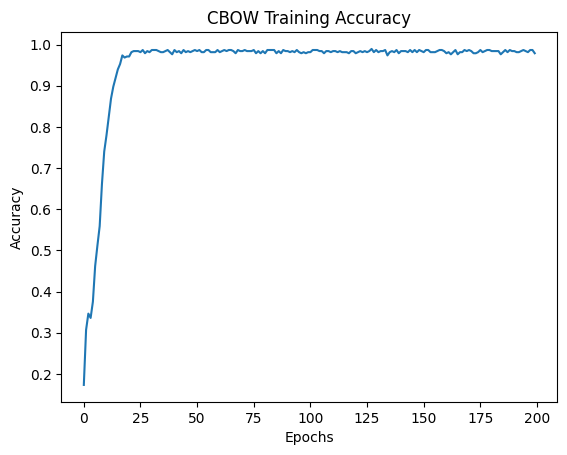

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 9: Plot training accuracy

plt.plot(history.history["accuracy"])

plt.title("CBOW Training Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.show()

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 10: Define function to predict target word from context words

def predict_word(context):

    ids = np.array([[word_to_id[w] for w in context]])

    prediction = model.predict(ids, verbose=0)

    index = np.argmax(prediction)

    return id_to_word[index]

In [ ]:
# PS 28: CBOW Model for Word Prediction
# Step 11: Test the model with context words

context = ["is", "an", "point", "of"]

print("Context:", context)

print("Actual Word: important")

print("Predicted Word:", predict_word(context))

Context: ['is', 'an', 'point', 'of']
Actual Word: important
Predicted Word: important
